# Uncertainty Modelling – the Ensemble Approach
**Advanced Learning Paradigms for AI · IIT Kharagpur · Group demo, 12 Oct 2026**
Adusumalli Achyutha Saharsh (24BT10013) · Reesh (24BT10049) · Venkata Sai Praneeth Tadi (24IM10067)

An ensemble $\{h_1,\dots,h_M\}$ approximates the distribution over hypotheses $p(h\mid D)$ (lecture slides 30–35).
From the members' predictions we get **total** uncertainty and split it into an
**aleatoric** part (noise in the data – irreducible) and an **epistemic** part (lack of knowledge – reducible):

$$\underbrace{H\Big[\tfrac1M\sum_m p(y\mid x,h_m)\Big]}_{U(x):\ \text{entropy of the average}}
= \underbrace{\tfrac1M\sum_m H\big[p(y\mid x,h_m)\big]}_{AU(x):\ \text{average of the entropies}}
+ \underbrace{I(y;h\mid x,D)}_{EU(x)\,=\,U-AU}$$

This notebook walks through the four experiments behind our slides. Everything runs on a laptop CPU in a few
minutes; the slow parts (training 10 CNNs, the data-size sweep) load saved results unless `RUN_SLOW = True`.

In [1]:
import os, sys, json, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "experiments")]

import numpy as np
import matplotlib.pyplot as plt
import torch

from ensemble_uq import (ParallelMLPEnsemble, GaussianEnsemble, LaplaceRandomForest, MCEnsemble, DeepEnsemble,
                         decompose_classification, member_table)
from ensemble_uq.data import grid_2d, make_toy_2d, make_regression_1d, regression_truth, regression_noise_std, REGRESSION_SUPPORT
from ensemble_uq.models import MLP, SmallCNN
from ensemble_uq.plotting import set_style, uncertainty_map, member_boundaries, regression_panels
from ensemble_uq import plotting as P

RUN_SLOW = False          # True = recompute the slow experiments instead of loading saved results
torch.set_num_threads(1)  # tiny models train fastest on one thread
set_style()
print("torch", torch.__version__)

torch 2.14.1+cu130


## 1 · The whole method on two toy inputs
Each row is one ensemble member's predictive distribution for the same input $x$ (the table on lecture slide 33).

In [2]:
agree_coin_flip = np.array([[0.5, 0.5]] * 5)                      # all members: "it's 50/50"
confident_disagree = np.array([[0.99, 0.01], [0.01, 0.99]] * 2 + [[0.99, 0.01]])  # members contradict each other

for name, probs in [("members agree it is a coin flip", agree_coin_flip),
                    ("members confidently disagree", confident_disagree)]:
    table, summary = member_table(probs, class_names=["p(y=1)", "p(y=2)"])
    print(f"--- {name}")
    print(table.round(3).to_string())
    print({k.split(' =')[0]: round(v, 3) for k, v in summary.items()}, "\n")

--- members agree it is a coin flip
         p(y=1)  p(y=2)  entropy
h1          0.5     0.5      1.0
h2          0.5     0.5      1.0
h3          0.5     0.5      1.0
h4          0.5     0.5      1.0
h5          0.5     0.5      1.0
average     0.5     0.5      1.0
{'U (total)': 1.0, 'AU (aleatoric)': 1.0, 'EU (epistemic)': 0.0} 

--- members confidently disagree
         p(y=1)  p(y=2)  entropy
h1        0.990   0.010    0.081
h2        0.010   0.990    0.081
h3        0.990   0.010    0.081
h4        0.010   0.990    0.081
h5        0.990   0.010    0.081
average   0.598   0.402    0.972
{'U (total)': 0.972, 'AU (aleatoric)': 0.081, 'EU (epistemic)': 0.891} 



Same total uncertainty (≈1 bit) – completely different reasons. In the first case more data would not help
(the label really is random); in the second it would.

## 2 · Where does each kind of uncertainty live? (2D toy classification)
Two overlapping Gaussian classes (lecture's red vs black). We train a **Deep Ensemble** of 10 small MLPs
(different random initialisations), a **Random Forest** with Laplace-corrected leaves (Shaker & Hüllermeier 2020),
and **MC DropConnect** (one network, 50 random weight masks at test time – an *implicit* ensemble).

trained and evaluated 3 ensembles in 5.1s


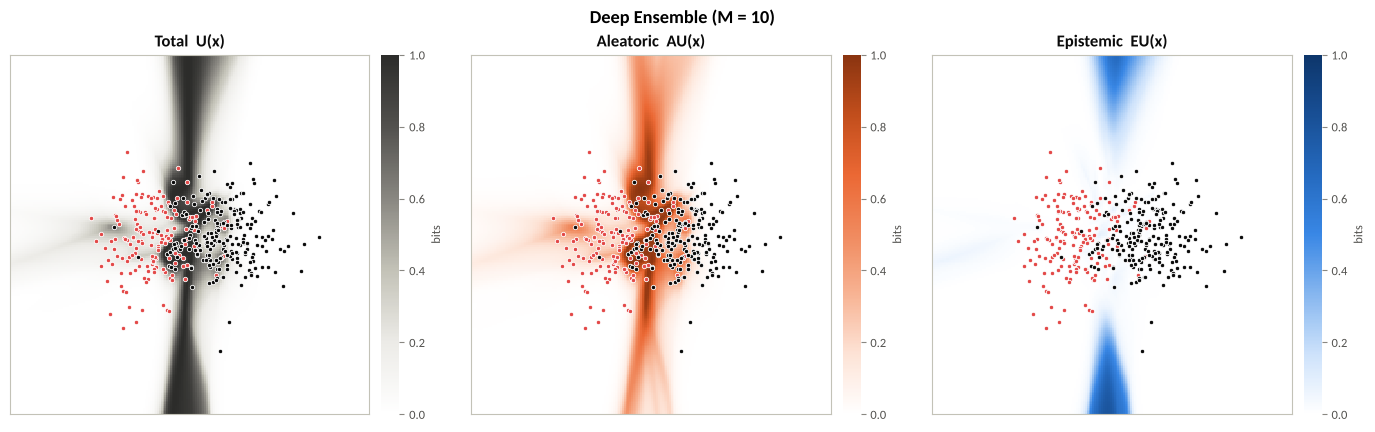

In [3]:
from e1_toy_classification import fit_methods, QUERIES

X, y = make_toy_2d("blobs", n=400, noise=1.0, seed=0)
xx, yy, grid = grid_2d(6.0, 200)
t0 = time.time()
methods = fit_methods(X, y)            # Deep Ensemble (M=10), Random Forest (100 trees), MC DropConnect (50 passes)
member_p = {name: m.member_probs(grid) for name, m in methods.items()}
decs = {name: decompose_classification(p) for name, p in member_p.items()}
print(f"trained and evaluated 3 ensembles in {time.time() - t0:.1f}s")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
for ax, kind in zip(axes, ("total", "aleatoric", "epistemic")):
    uncertainty_map(ax, xx, yy, getattr(decs["Deep Ensemble"], kind), kind, X, y)
fig.suptitle("Deep Ensemble (M = 10)", fontweight="bold"); fig.tight_layout(); plt.show()

* **Aleatoric** (orange) sits where the classes overlap: every member says "about 50/50".
* **Epistemic** (blue) appears far from the data, where the members' decision boundaries fan out.
* Far left / far right the members all agree, so EU stays low there: *EU measures disagreement, not distance from the data.*

The members' boundaries make the second point visible:

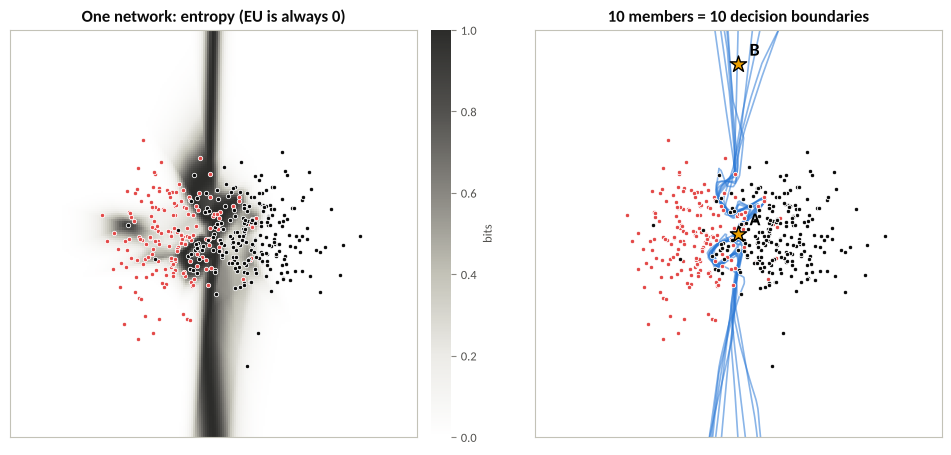

Query A at (0.0, 0.0):  U (total) = 0.962,  AU (aleatoric) = 0.954,  EU (epistemic) = 0.008
Query B at (0.0, 5.0):  U (total) = 0.994,  AU (aleatoric) = 0.483,  EU (epistemic) = 0.511


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
single = decompose_classification(member_p["Deep Ensemble"][:1])   # member 1 on its own
uncertainty_map(axes[0], xx, yy, single.total, "total", X, y, title="One network: entropy (EU is always 0)")
member_boundaries(axes[1], xx, yy, member_p["Deep Ensemble"], X, y)
for q, (qx, qy) in QUERIES.items():
    axes[1].scatter([qx], [qy], s=150, marker="*", color=P.YELLOW, edgecolors="k", zorder=6)
    axes[1].annotate(q, (qx, qy), xytext=(8, 6), textcoords="offset points", fontsize=13, fontweight="bold")
axes[1].set_title("10 members = 10 decision boundaries")
fig.tight_layout(); plt.show()

for q, point in QUERIES.items():
    probs = methods["Deep Ensemble"].member_probs(np.array([point], dtype=np.float32))[:, 0, :]
    table, summary = member_table(probs, class_names=["p(red)", "p(black)"])
    print(f"Query {q} at {point}:  " + ",  ".join(f"{k.split(' =')[0]} = {v:.3f}" for k, v in summary.items()))

Query **A** (inside the overlap) and query **B** (far above the data) both carry about one bit of total uncertainty,
but A is almost purely aleatoric while B is about half epistemic.

### Three ways to build the committee

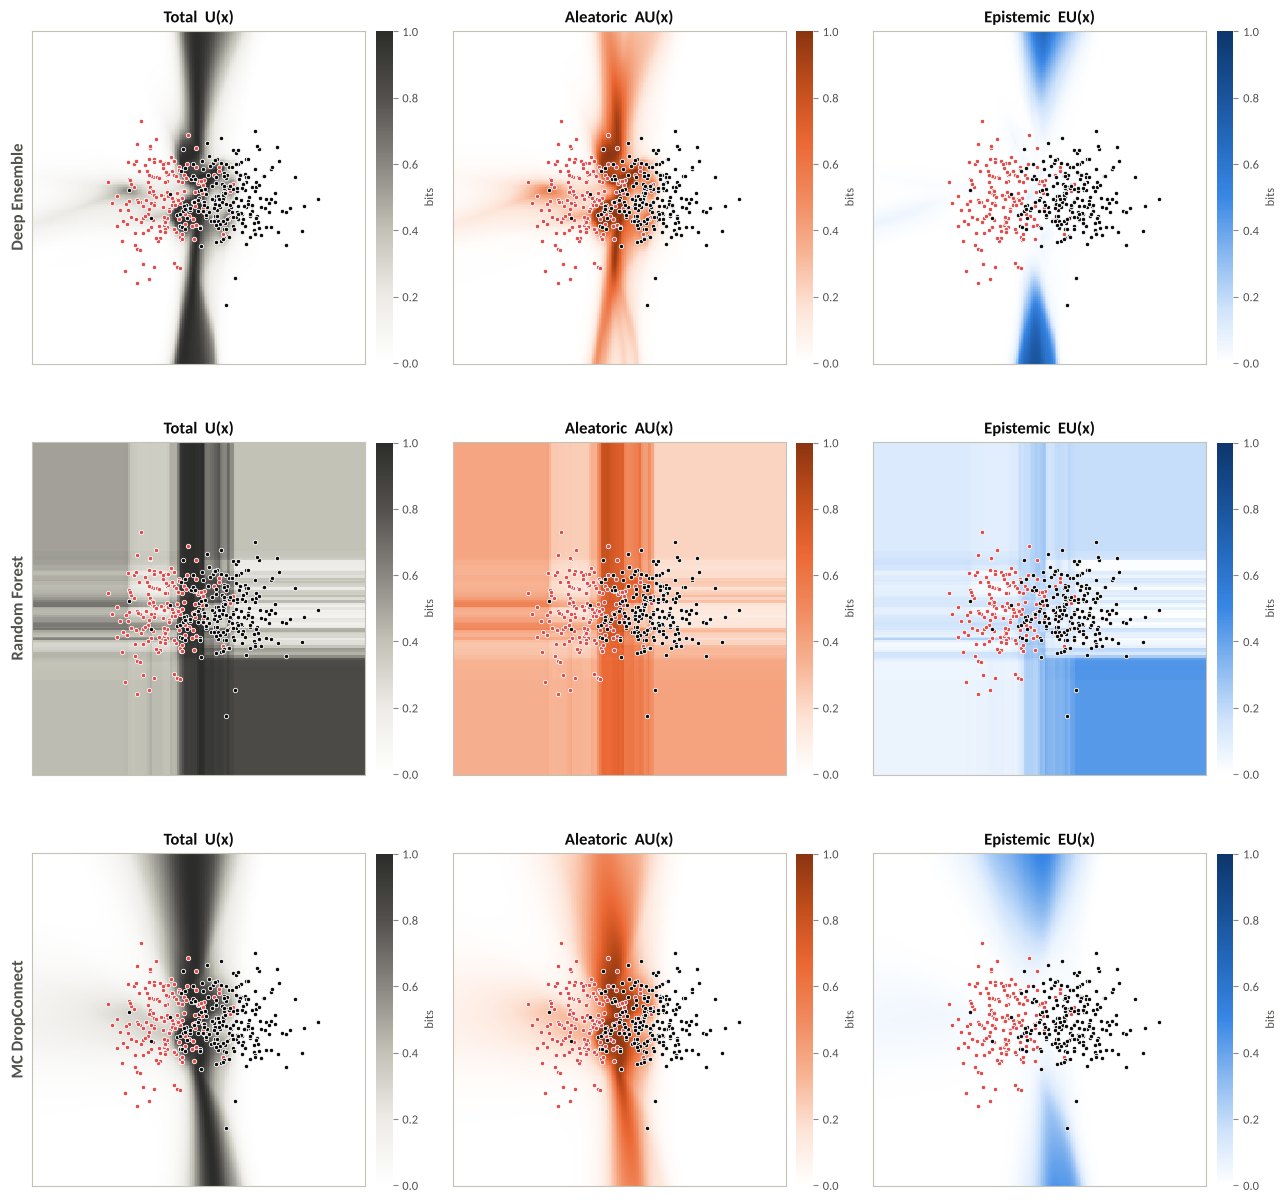

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(13, 12.5))
for row, (name, dec) in zip(axes, decs.items()):
    for ax, kind in zip(row, ("total", "aleatoric", "epistemic")):
        uncertainty_map(ax, xx, yy, getattr(dec, kind), kind, X, y)
    row[0].set_ylabel(name, fontsize=12, fontweight="bold")
fig.tight_layout(); plt.show()

The random forest's uncertainty is axis-aligned and, because of the Laplace correction on small leaves, its AU
never drops to zero – every tree hedges a little. The implicit ensemble (DropConnect) gives a smoother, weaker
version of the Deep Ensemble's picture at the training cost of one network.

## 3 · Regression: splitting the error bar
Each member predicts a mean **and** a variance, $\mathcal N(\mu_m(x), \sigma_m^2(x))$, trained with the Gaussian
negative log-likelihood (Lakshminarayanan et al., 2017). Law of total variance:
$\ \mathrm{Var}[y\mid x] = \underbrace{\tfrac1M\sum_m\sigma_m^2(x)}_{\text{aleatoric}} + \underbrace{\tfrac1M\sum_m(\mu_m(x)-\bar\mu(x))^2}_{\text{epistemic}}$.

5 mean/variance networks trained in 5.5s


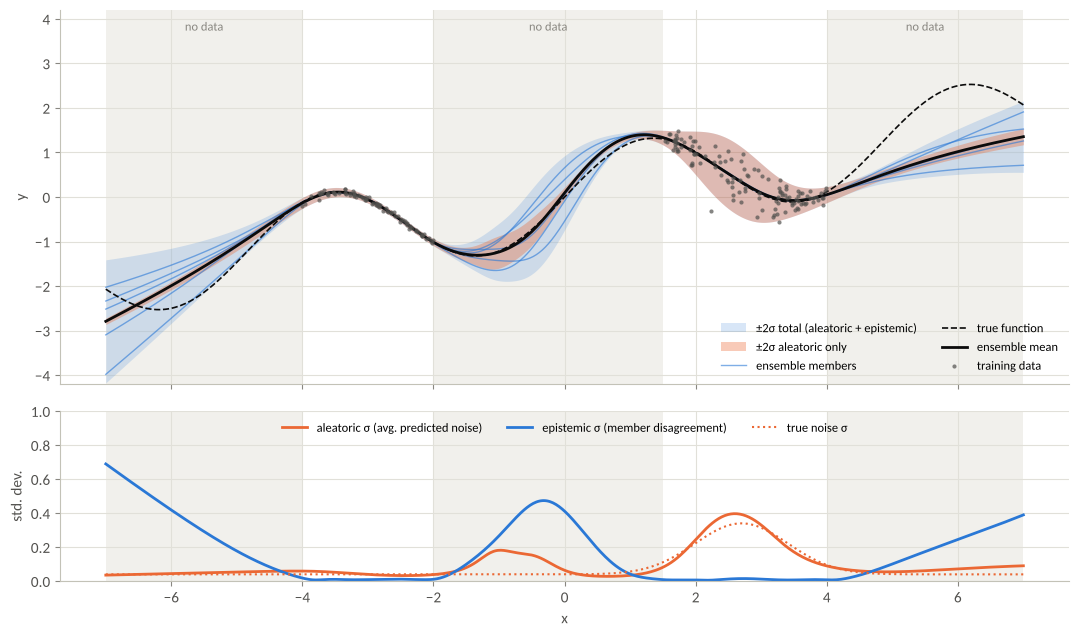

In [6]:
x, yr = make_regression_1d(200, seed=0)            # noisy bump around x = 2.7, no data for -2 < x < 1.5
t0 = time.time()
reg = GaussianEnsemble(n_members=5, seed=0).fit(x, yr, epochs=2500, lr=3e-3, warmup_epochs=300)
print(f"5 mean/variance networks trained in {time.time() - t0:.1f}s")
x_grid = np.linspace(-7, 7, 600).astype(np.float32)
means, _ = reg.member_moments(x_grid)
d = reg.predict(x_grid)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
regression_panels(a1, a2, x_grid, d, x, yr, truth=regression_truth(x_grid), noise_std=regression_noise_std(x_grid),
                  member_means=means, support=REGRESSION_SUPPORT)
a1.set_ylim(-4.2, 4.2); a1.legend(loc="lower right", fontsize=9, ncol=2)
a2.set_ylim(0, 1.0); a2.legend(loc="upper center", fontsize=9, ncol=3)
fig.tight_layout(); plt.show()

Orange follows the true noise (dotted) wherever there is data; blue rises in the gap and outside the data.

### Is epistemic uncertainty really *reducible*?
Constant noise $\sigma = 0.25$ (so the irreducible variance is exactly $0.0625$), $N = 16 \dots 2048$ training points, 5 seeds each.

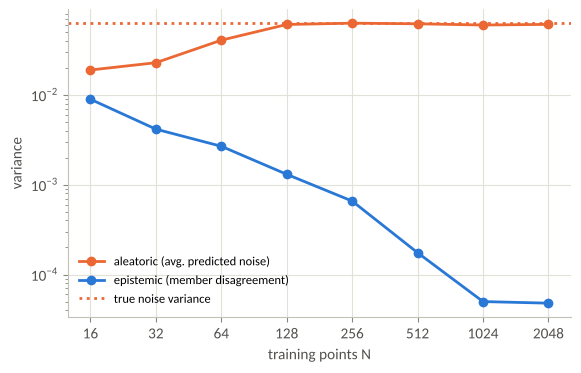

epistemic variance shrinks 186x from N=16 to N=2048; aleatoric settles at 0.0608 (truth 0.0625)


In [7]:
import e2_regression
res = e2_regression.run() if RUN_SLOW else json.loads((ROOT / "results/metrics/e2_regression.json").read_text())
curves = res[1] if RUN_SLOW else res["more_data"]   # run() returns (ensemble, curves)
n = np.array(curves["n"])
alea, epi = np.array(curves["aleatoric_var"])[:, 0], np.array(curves["epistemic_var"])[:, 0]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(n, alea, "o-", color=P.ALEATORIC, label="aleatoric (avg. predicted noise)")
ax.plot(n, epi, "o-", color=P.EPISTEMIC, label="epistemic (member disagreement)")
ax.axhline(curves["true_noise_var"], color=P.ALEATORIC, ls=":", label="true noise variance")
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xticks(n); ax.set_xticklabels(n)
ax.set_xlabel("training points N"); ax.set_ylabel("variance"); ax.legend(fontsize=9); plt.show()
print(f"epistemic variance shrinks {epi[0] / epi[-1]:.0f}x from N={n[0]} to N={n[-1]}; "
      f"aleatoric settles at {alea[-1]:.4f} (truth 0.0625)")

## 4 · Does the uncertainty know when the model is wrong? (accuracy–rejection, lecture slide 37)
Reject the most uncertain test points and measure accuracy on the rest; a useful measure gives a rising curve.
Diabetes (Pima) and SPECT heart, 10 random 70/30 splits (≈30 s to recompute).

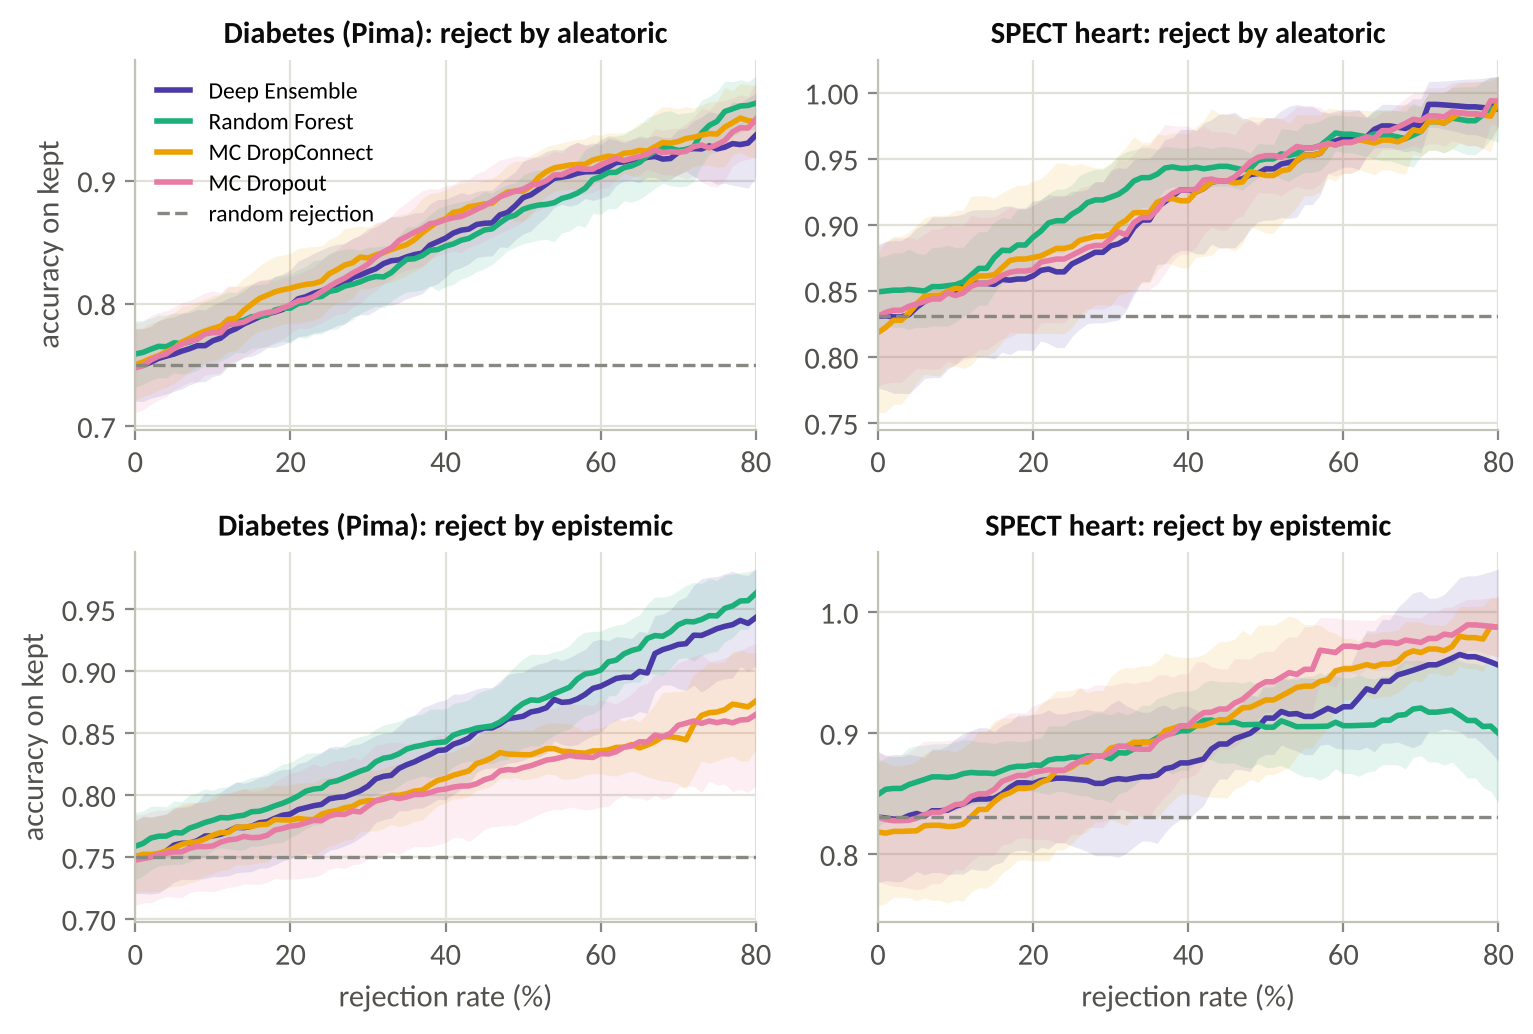

diabetes {'Deep Ensemble': {'aleatoric': 0.851, 'epistemic': 0.84}, 'Random Forest': {'aleatoric': 0.851, 'epistemic': 0.852}, 'MC DropConnect': {'aleatoric': 0.862, 'epistemic': 0.811}, 'MC Dropout': {'aleatoric': 0.857, 'epistemic': 0.806}}
spect {'Deep Ensemble': {'aleatoric': 0.915, 'epistemic': 0.89}, 'Random Forest': {'aleatoric': 0.927, 'epistemic': 0.892}, 'MC DropConnect': {'aleatoric': 0.916, 'epistemic': 0.902}, 'MC Dropout': {'aleatoric': 0.917, 'epistemic': 0.911}}


In [8]:
import e3_accuracy_rejection as e3
if RUN_SLOW:
    results = e3.run()
else:
    saved = json.loads((ROOT / "results/metrics/e3_accuracy_rejection.json").read_text())
    as_arrays = lambda d: {k: np.array(v) if isinstance(v, list) else v for k, v in d.items()}
    results = {ds: {name: {m: as_arrays(r[m]) if isinstance(r[m], dict) else r[m] for m in r}
                    for name, r in per.items()} for ds, per in saved["curves"].items()}
e3.plot(results, measures=("aleatoric", "epistemic"), fname="e3_accuracy_rejection.png")
from IPython.display import Image, display
display(Image(filename=str(ROOT / "results/figures/e3_accuracy_rejection.png"), width=900))
for ds in results:
    print(ds, {name: {m: round(results[ds][name][m]["area"], 3) for m in ("aleatoric", "epistemic")}
               for name in results[ds]})

On these in-distribution test sets most mistakes come from overlapping classes, so rejecting by **aleatoric**
uncertainty helps at least as much as rejecting by epistemic uncertainty – the same pattern as in the lecture.

## 5 · Images: 10 CNNs on MNIST meet things they have never seen
Ten small CNNs (≈106k parameters each), each trained for 10 epochs from its own random initialisation.
The weights are in `checkpoints/`; set `RUN_SLOW = True` to retrain (≈25 min on a CPU).

In [9]:
from ensemble_uq.data import load_mnist, load_fashion_mnist, normalize, rotate, FASHION_CLASSES
from ensemble_uq.metrics import accuracy, nll, brier, expected_calibration_error, ood_auroc
from e4_mnist_ood import train_or_load

Xtr, ytr = load_mnist(train=True)          # downloads MNIST / Fashion-MNIST on first use
Xte, yte = load_mnist(train=False)
Xood, yood = load_fashion_mnist(train=False)
torch.set_num_threads(os.cpu_count() or 1)   # CNNs: use every core
de, mc = train_or_load(Xtr, ytr, retrain=RUN_SLOW)

t0 = time.time()
P_in, P_out = de.member_probs(normalize(Xte)), de.member_probs(normalize(Xood))     # (10, 10000, 10)
M_in, M_out = mc.member_probs(normalize(Xte)), mc.member_probs(normalize(Xood))
print(f"predictions for 2 x 10,000 images in {time.time() - t0:.0f}s")
y_np = yte.numpy()
rows = {"Single network": P_in[0], "Deep Ensemble M=5": P_in[:5].mean(0), "Deep Ensemble M=10": P_in.mean(0),
        "MC Dropout (10 passes)": M_in.mean(0)}
print(f"{'':24s} accuracy   NLL     Brier   ECE")
for name, p in rows.items():
    print(f"{name:24s} {accuracy(p, y_np):.4f}   {nll(p, y_np):.4f}  {brier(p, y_np):.4f}  {expected_calibration_error(p, y_np):.4f}")

predictions for 2 x 10,000 images in 80s
                         accuracy   NLL     Brier   ECE
Single network           0.9886   0.0388  0.0171  0.0051
Deep Ensemble M=5        0.9927   0.0232  0.0116  0.0044
Deep Ensemble M=10       0.9928   0.0211  0.0108  0.0040
MC Dropout (10 passes)   0.9904   0.0380  0.0160  0.0156


In [10]:
d_in, d_out = decompose_classification(P_in), decompose_classification(P_out)
s_in, s_out = decompose_classification(P_in[:1]), decompose_classification(P_out[:1])
m_in, m_out = decompose_classification(M_in), decompose_classification(M_out)
print("OOD detection AUROC  (MNIST test = in, Fashion-MNIST test = out)")
print(f"  single network, entropy        : {ood_auroc(s_in.total, s_out.total):.3f}")
for name, a, b in [("Deep Ensemble", d_in, d_out), ("MC Dropout", m_in, m_out)]:
    print(f"  {name:14s} total / AU / EU : " + " / ".join(f"{ood_auroc(getattr(a, k), getattr(b, k)):.3f}"
                                                     for k in ("total", "aleatoric", "epistemic")))
print(f"\nFashion items the single network calls a digit with >99% confidence: {(s_out.confidence > 0.99).mean():.1%}")

OOD detection AUROC  (MNIST test = in, Fashion-MNIST test = out)
  single network, entropy        : 0.973
  Deep Ensemble  total / AU / EU : 0.988 / 0.988 / 0.985
  MC Dropout     total / AU / EU : 0.981 / 0.983 / 0.961

Fashion items the single network calls a digit with >99% confidence: 16.2%


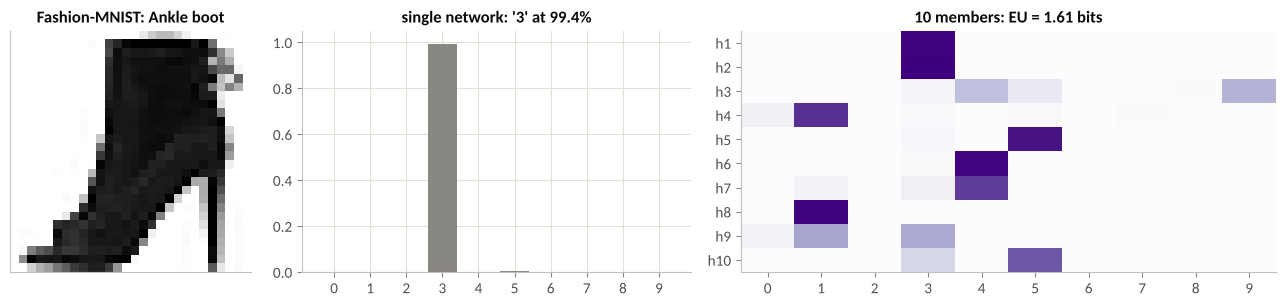

In [11]:
# the overconfident example from our first slide
sure = np.where(s_out.confidence > 0.99)[0]
i = int(sure[np.argmax(d_out.epistemic[sure])]) if len(sure) else int(np.argmax(d_out.epistemic))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), gridspec_kw={"width_ratios": [1, 1.6, 2.2]})
axes[0].imshow(Xood[i, 0], cmap="gray_r"); axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].set_title(f"Fashion-MNIST: {FASHION_CLASSES[int(yood[i])]}")
axes[1].bar(range(10), P_out[0, i], color=P.MUTED); axes[1].set_xticks(range(10)); axes[1].set_ylim(0, 1.05)
axes[1].set_title(f"single network: '{P_out[0, i].argmax()}' at {P_out[0, i].max():.1%}")
axes[2].imshow(P_out[:, i], cmap="Purples", vmin=0, vmax=1, aspect="auto"); axes[2].grid(False)
axes[2].set_xticks(range(10)); axes[2].set_yticks(range(10)); axes[2].set_yticklabels([f"h{m+1}" for m in range(10)])
axes[2].set_title(f"10 members: EU = {d_out.epistemic[i]:.2f} bits")
fig.tight_layout(); plt.show()

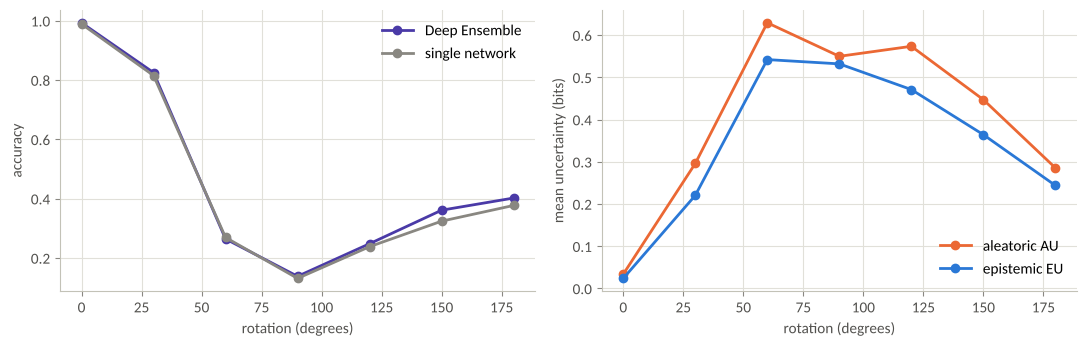

In [12]:
# dataset shift: rotate 1,000 test digits
angles = list(range(0, 181, 30))
eu, au, acc_de, acc_single = [], [], [], []
for a in angles:
    Pr = de.member_probs(normalize(rotate(Xte[:1000], a)))
    dr = decompose_classification(Pr)
    eu.append(dr.epistemic.mean()); au.append(dr.aleatoric.mean())
    acc_de.append(accuracy(Pr.mean(0), y_np[:1000])); acc_single.append(accuracy(Pr[0], y_np[:1000]))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(angles, acc_de, "o-", color=P.METHOD_COLORS["Deep Ensemble"], label="Deep Ensemble"); axes[0].plot(angles, acc_single, "o-", color=P.MUTED, label="single network")
axes[0].set_xlabel("rotation (degrees)"); axes[0].set_ylabel("accuracy"); axes[0].legend()
axes[1].plot(angles, au, "o-", color=P.ALEATORIC, label="aleatoric AU"); axes[1].plot(angles, eu, "o-", color=P.EPISTEMIC, label="epistemic EU")
axes[1].set_xlabel("rotation (degrees)"); axes[1].set_ylabel("mean uncertainty (bits)"); axes[1].legend()
fig.tight_layout(); plt.show()

## 6 · Take-aways
1. **One recipe, many committees.** Deep ensembles, bagging, random forests, MC Dropout / DropConnect all give a
   table of member predictions; the same three formulas turn it into total, aleatoric and epistemic uncertainty.
2. **Aleatoric = members agree it is noisy; epistemic = members disagree.** More data shrinks the second, not the first.
3. **Deep ensembles are a strong, simple baseline** – better accuracy and NLL than a single network and clearly better
   at flagging inputs they have never seen – at M× the training and prediction cost.
4. **Caveats.** EU measures *disagreement*, not distance from the data (members can agree confidently far away);
   with very little data the split itself is unreliable; and the entropy-based decomposition has known theoretical
   weaknesses (Wimmer et al., 2023).

Live version: `streamlit run app/streamlit_app.py`